# 03 特徴量分析

Walking時の加速度特徴量について、
WalkingAbility（1・2）による違いを確認する。

## 1. 前処理済みデータの読み込み

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 前処理済みデータを読み込み
df = pd.read_csv("../data/processed/walking_model_data.csv")

print("データサイズ:", df.shape)
display(df.head())

print("\nWalkingAbilityの内訳:")
print(df["WalkingAbility"].value_counts())

データサイズ: (14, 103)


,Observation_ID,X_Dynamic_Freq.Min,X_Dynamic_Freq.Max,X_Dynamic_Freq.AbsMean,X_Dynamic_Freq.IQR,X_Dynamic_Amp.Min,X_Dynamic_Amp.Max,X_Dynamic_Amp.AbsMean,X_Dynamic_Amp.IQR,Y_Dynamic_Freq.Min,...,Z_Static_filt.AbsMean,Z_Static_filt.IQR,Z_Static_filt.Skewness,Z_Static_filt.Kurtosis,Z_Static_filt.Entropy,Z_Static_filt.Peak_Trough.x,Z_Static_filt.Peak_Trough.y,Age_Days,SexFM,WalkingAbility
0,11_4_NB_03.04,0.001051,0.048974,0.024727,0.023615,0.000515,0.284558,0.027344,0.020816,0.001077,...,1.051431,0.025700,0.447392,2.600404,5.703547,159.622405,-1.006637,48,M,1
1,11_4_NB_12.03,0.001189,0.049014,0.024766,0.023685,0.002090,0.477719,0.061802,0.069582,0.001102,...,1.005759,0.047855,0.687088,3.842122,5.694262,146.063662,-0.846432,26,M,1
2,12_BB_R_12.03,0.001250,0.048750,0.024565,0.024031,0.000151,0.070775,0.007634,0.007825,0.001063,...,0.957737,0.035962,0.619064,2.663877,5.708719,123.140922,-0.903687,26,M,2
3,21_OO_H_03.04,0.001015,0.048899,0.024565,0.024014,0.001559,0.528781,0.047490,0.034830,0.001102,...,1.027542,0.033554,0.517441,3.056917,5.706444,128.814738,-0.898507,48,F,1
4,21_OO_H_12.03,0.001161,0.048951,0.024712,0.024191,0.000425,0.199725,0.021543,0.019314,0.001198,...,1.006572,0.055158,0.586681,3.091001,5.692691,155.919676,-0.896799,26,F,1



WalkingAbilityの内訳:
WalkingAbility
1    12
2     2
Name: count, dtype: int64


## 2. WalkingAbility別の特徴量比較

WalkingAbilityごとに加速度特徴量の平均値を算出し、
歩行能力によって違いが見られる特徴量を探索する。

In [2]:
# ID・ラベル等を除き、加速度特徴量だけを取得
exclude_cols = [
    "Observation_ID",
    "Age_Days",
    "SexFM",
    "WalkingAbility"
]

feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

print("特徴量数:", len(feature_cols))

# WalkingAbilityごとの平均
ability_mean = (
    df.groupby("WalkingAbility")[feature_cols]
    .mean()
)

display(ability_mean)

特徴量数: 99


,X_Dynamic_Freq.Min,X_Dynamic_Freq.Max,X_Dynamic_Freq.AbsMean,X_Dynamic_Freq.IQR,X_Dynamic_Amp.Min,X_Dynamic_Amp.Max,X_Dynamic_Amp.AbsMean,X_Dynamic_Amp.IQR,Y_Dynamic_Freq.Min,Y_Dynamic_Freq.Max,...,Y_Static_filt.Peak_Trough.y,Z_Static_filt.Min,Z_Static_filt.Max,Z_Static_filt.AbsMean,Z_Static_filt.IQR,Z_Static_filt.Skewness,Z_Static_filt.Kurtosis,Z_Static_filt.Entropy,Z_Static_filt.Peak_Trough.x,Z_Static_filt.Peak_Trough.y
WalkingAbility,,,,,,,,,,,,,,,,,,,,,
1,0.001088,0.048896,0.02473,0.023759,0.000781,0.280013,0.030899,0.028619,0.001122,0.048906,...,0.102196,-1.044982,-0.910310,0.996512,0.040450,0.463608,2.954893,5.684122,144.267891,-0.906361
2,0.001206,0.048722,0.02461,0.023675,0.000375,0.109578,0.011552,0.010370,0.001136,0.048778,...,0.176751,-1.024902,-0.945999,0.993866,0.029723,0.655474,2.788323,5.680300,124.671783,-0.942797


## 3. WalkingAbilityによる特徴量の差

特徴量ごとに値のスケールが異なるため、
WalkingAbility 1と2の単純な平均との差では比較しにくい。

そこで、各特徴量について全観測の標準偏差で平均値の差を割り、
標準化した差を算出する。

※ WalkingAbility 2は2観測のみのため、
ここでは統計的な結論ではなく探索的な特徴量比較として扱う。

In [3]:
# WalkingAbility 1と2の平均値
mean_1 = ability_mean.loc[1]
mean_2 = ability_mean.loc[2]

# 各特徴量の標準偏差
feature_std = df[feature_cols].std()

# 標準化した平均値の差
standardized_diff = (
    (mean_2 - mean_1) / feature_std
)

# 絶対値が大きい順に並べる
diff_ranking = (
    standardized_diff
    .abs()
    .sort_values(ascending=False)
)

print("WalkingAbilityによる差が大きい特徴量 TOP20")
display(diff_ranking.head(20))

WalkingAbilityによる差が大きい特徴量 TOP20


SVM.IQR                    1.884899
X_Dynamic_filt.IQR         1.814851
X_Dynamic_filt.AbsMean     1.790280
X_Dynamic_Freq.Max         1.789308
SVM.Skewness               1.751796
Y_Dynamic_filt.Skewness    1.742864
SVM.Kurtosis               1.730974
Z_Dynamic_filt.AbsMean     1.688025
Z_Dynamic_filt.IQR         1.623708
SVM.AbsMean                1.615537
Y_Dynamic_filt.Kurtosis    1.611989
X_Static_filt.Min          1.571376
Z_Dynamic_filt.Skewness    1.559428
Pitch.Max                  1.505155
X_Dynamic_filt.Min         1.494522
SVM.Min                    1.474113
X_Dynamic_filt.Entropy     1.451891
Y_Dynamic_filt.IQR         1.450525
Y_Dynamic_Amp.IQR          1.445289
Y_Dynamic_Freq.IQR         1.445289
dtype: float64

## 4. 上位特徴量の分布確認

標準化した平均値の差が最も大きかった特徴量について、
WalkingAbilityごとの実際の値を可視化する。

平均値だけでなく個々の観測値を確認することで、
WalkingAbility 2の少数データがどのような分布を示しているか確認する。

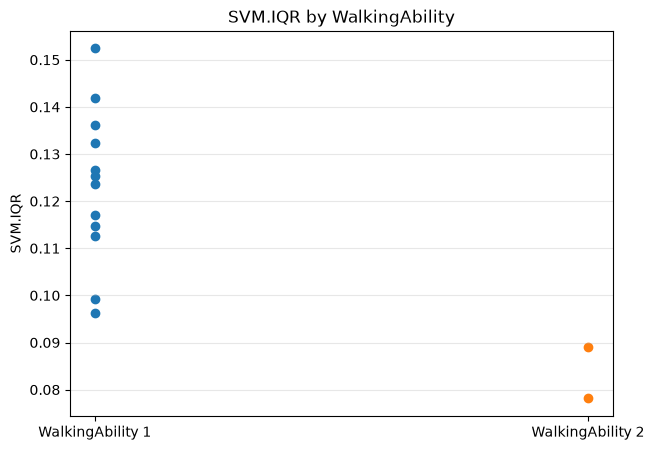

WalkingAbility 1


count    12.000000
mean      0.123196
std       0.016493
min       0.096344
25%       0.114139
50%       0.124462
75%       0.133305
max       0.152408
Name: SVM.IQR, dtype: float64

WalkingAbility 2


count    2.000000
mean     0.083583
std      0.007707
min      0.078134
25%      0.080858
50%      0.083583
75%      0.086308
max      0.089033
Name: SVM.IQR, dtype: float64

In [4]:
import matplotlib.pyplot as plt

feature = "SVM.IQR"

group1 = df[df["WalkingAbility"] == 1][feature]
group2 = df[df["WalkingAbility"] == 2][feature]

plt.figure(figsize=(7, 5))

plt.scatter(
    [1] * len(group1),
    group1,
    label="WalkingAbility 1"
)

plt.scatter(
    [2] * len(group2),
    group2,
    label="WalkingAbility 2"
)

plt.xticks([1, 2], ["WalkingAbility 1", "WalkingAbility 2"])
plt.ylabel(feature)
plt.title("SVM.IQR by WalkingAbility")
plt.grid(axis="y", alpha=0.3)

plt.show()

print("WalkingAbility 1")
display(group1.describe())

print("WalkingAbility 2")
display(group2.describe())

In [5]:
# 差が大きかった上位5特徴量
top5_features = diff_ranking.head(5).index.tolist()

print("上位5特徴量:")
for feature in top5_features:
    print(feature)

# WalkingAbilityごとの平均値
top5_mean = (
    df.groupby("WalkingAbility")[top5_features]
    .mean()
    .T
)

top5_mean["difference"] = top5_mean[2] - top5_mean[1]

display(top5_mean)

上位5特徴量:
SVM.IQR
X_Dynamic_filt.IQR
X_Dynamic_filt.AbsMean
X_Dynamic_Freq.Max
SVM.Skewness


WalkingAbility,1,2,difference
SVM.IQR,0.123196,0.083583,-0.039613
X_Dynamic_filt.IQR,0.101906,0.059481,-0.042425
X_Dynamic_filt.AbsMean,0.077410,0.047527,-0.029883
X_Dynamic_Freq.Max,0.048896,0.048722,-0.000173
SVM.Skewness,1.692815,2.190898,0.498083


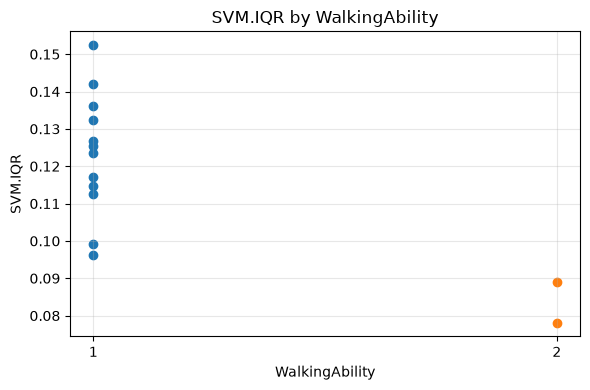

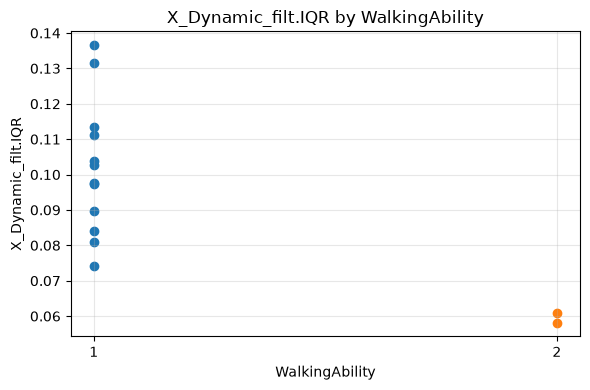

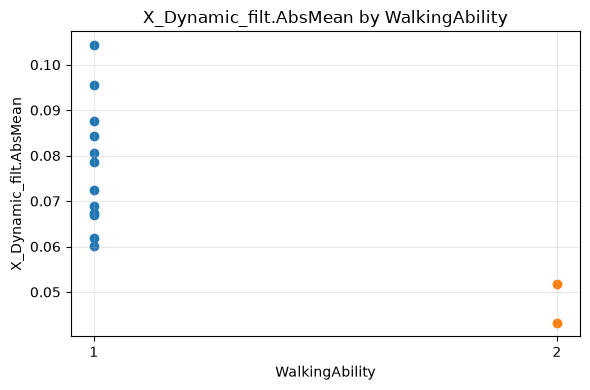

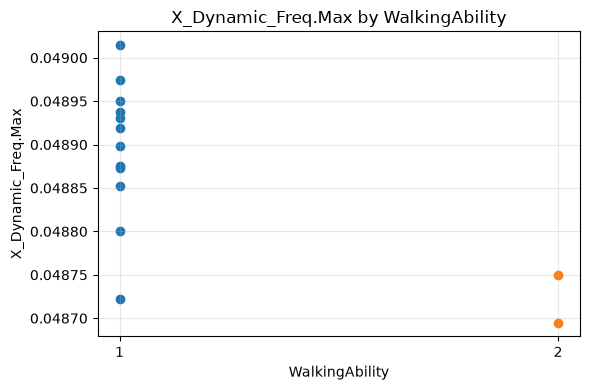

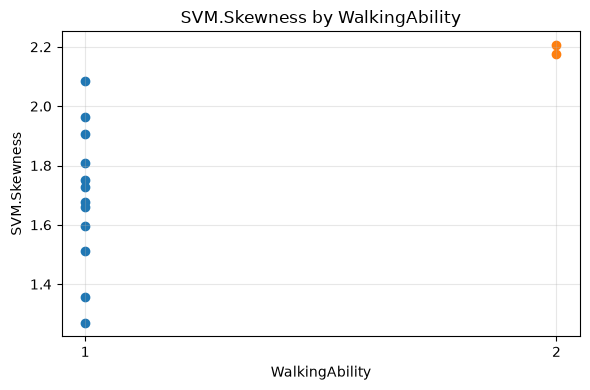

In [10]:
import matplotlib.pyplot as plt

# 上位5特徴量をWalkingAbility別に可視化
for feature in top5_features:
    plt.figure(figsize=(6, 4))

    for ability in sorted(df["WalkingAbility"].unique()):
        values = df.loc[df["WalkingAbility"] == ability, feature]

        x = [ability] * len(values)
        plt.scatter(x, values, label=f"WalkingAbility {ability}")

    plt.title(f"{feature} by WalkingAbility")
    plt.xlabel("WalkingAbility")
    plt.ylabel(feature)
    plt.xticks([1, 2])
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        "../images/feature_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()



In [7]:
# 上位特徴量同士の相関
top5_corr = df[top5_features].corr()

display(top5_corr.round(3))

,SVM.IQR,X_Dynamic_filt.IQR,X_Dynamic_filt.AbsMean,X_Dynamic_Freq.Max,SVM.Skewness
SVM.IQR,1.000,0.861,0.876,0.749,-0.529
X_Dynamic_filt.IQR,0.861,1.000,0.963,0.755,-0.376
X_Dynamic_filt.AbsMean,0.876,0.963,1.000,0.688,-0.279
X_Dynamic_Freq.Max,0.749,0.755,0.688,1.000,-0.427
SVM.Skewness,-0.529,-0.376,-0.279,-0.427,1.000


### 相関分析の結果

WalkingAbilityによる差が大きかった上位特徴量について相関を確認した。

X_Dynamic_filt.IQRとX_Dynamic_filt.AbsMeanの相関係数は0.963と非常に高く、
SVM.IQRについてもこれらの特徴量と強い正の相関が確認された。

このことから、歩行能力による差がみられた複数の特徴量が、
歩行時の動きの大きさや変動という共通した性質を捉えている可能性がある。

一方、SVM.Skewnessは他の上位特徴量と負の相関を示しており、
異なる側面を捉える特徴量である可能性がある。

ただし、WalkingAbility 2の観測数は2件と少ないため、
今回確認された傾向の一般化には注意が必要である。

In [8]:
# 機械学習に使用する特徴量候補
selected_features = [
    "SVM.IQR",
    "X_Dynamic_filt.AbsMean",
    "SVM.Skewness"
]

X = df[selected_features]
y = df["WalkingAbility"]

print("説明変数:", X.shape)
print("目的変数:", y.shape)

display(X.head())
print("\n目的変数の内訳:")
print(y.value_counts())

説明変数: (14, 3)
目的変数: (14,)


,SVM.IQR,X_Dynamic_filt.AbsMean,SVM.Skewness
0,0.117047,0.080632,1.659922
1,0.152408,0.104290,2.084485
2,0.078134,0.043260,2.205491
3,0.132324,0.087590,1.728251
4,0.112571,0.072534,1.752195



目的変数の内訳:
WalkingAbility
1    12
2     2
Name: count, dtype: int64


## 特徴量の選択

WalkingAbilityによる差が大きい特徴量について相関を確認した結果、
一部の特徴量には非常に強い相関がみられた。

特に、X_Dynamic_filt.IQRとX_Dynamic_filt.AbsMeanの相関係数は0.963であり、
類似した情報を持つ特徴量であると考えられる。

そこで、特徴量間の情報の重複を減らしながら、
WalkingAbilityとの違いを捉えるため、以下の3特徴量をモデルに使用する。

- SVM.IQR
- X_Dynamic_filt.AbsMean
- SVM.Skewness

これらは加速度のばらつき、大きさ、分布形状という
異なる側面を表す特徴量として選択した。